Código del lab de FabTest

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gplugins.tidy3d as gt
from scipy.signal import find_peaks
# Reference wavelength, our design wavelength
lambda0 = 1.55  # µm 
# Wavelength sweep for modal analysis
wavelength_modes = np.linspace(1.50, 1.605, 12)  # µm

# Wavelength sweep for ring spectral analysis
lambda_sweep = np.linspace(1.50, 1.605, 4001)  # µm

For simulation purposes, I will suppose the same cross section as the design lab

In [2]:
deep_waveguide = gt.modes.Waveguide(
    core_width=1.2,
    core_thickness=0.3,
    slab_thickness=0,
    core_material='sin',
    clad_material='sio2',
    wavelength=wavelength_modes,
    num_modes=4,
    max_grid_scaling=1.4,
    grid_resolution=20,
    cache_path='.cache/',
    precision='double',
)

# Calculate effective indices and TE fractions
#print('Effective indices:', deep_waveguide.n_eff)
#print('TE fractions:', deep_waveguide.fraction_te)

2026-11-20 00:34:40.204 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_f63f3ca3c6e50883.npz.


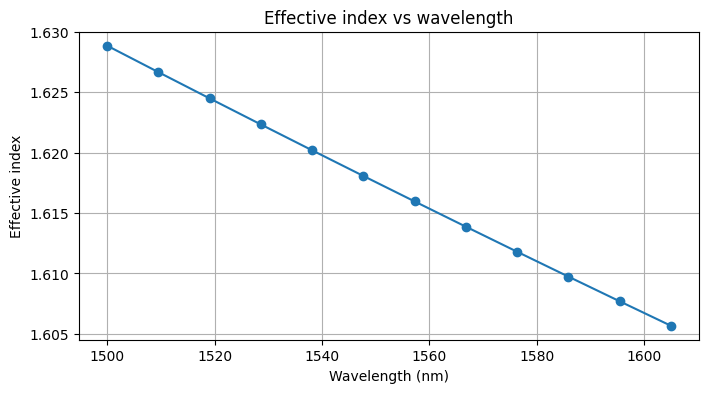

n_eff at 1550 nm = 1.61807


In [3]:
# Select fundamental TE-like mode
te_mode_index = 0

# Extract effective index
neff = np.real(
    np.asarray(deep_waveguide.n_eff)[:, te_mode_index]
)

# Plot effective index vs wavelength
plt.figure(figsize=(8, 4))
plt.plot(wavelength_modes * 1000, neff, 'o-')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Effective index')
plt.title('Effective index vs wavelength')
plt.grid(True)
plt.show()

# Effective index at 1550 nm
idx = np.argmin(np.abs(wavelength_modes - lambda0))
neff_1550 = neff[idx]

print(f'n_eff at 1550 nm = {neff_1550:.5f}')

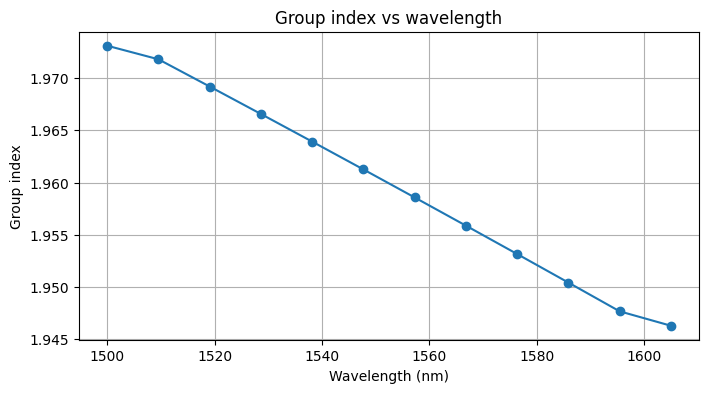

n_g at 1550 nm = 1.96126


In [4]:
# Numerical derivative of effective index
dneff_dlambda = np.gradient(neff, wavelength_modes)

# Calculate group index
ng = neff - wavelength_modes * dneff_dlambda

# Plot group index vs wavelength
plt.figure(figsize=(8, 4))
plt.plot(wavelength_modes * 1000, ng, 'o-')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Group index')
plt.title('Group index vs wavelength')
plt.grid(True)
plt.show()

# Group index at 1550 nm
ng_1550 = ng[idx]

print(f'n_g at 1550 nm = {ng_1550:.5f}')

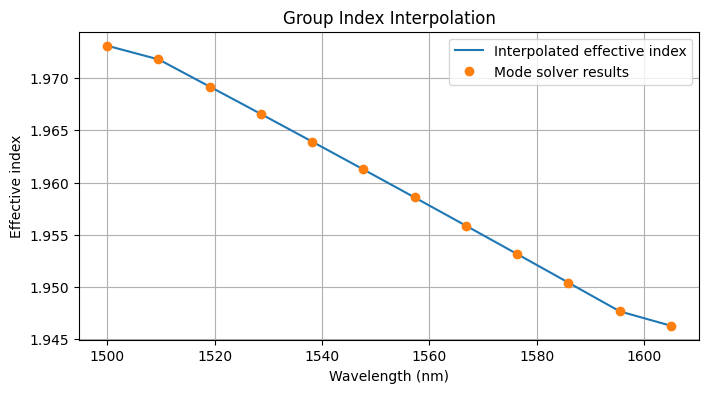

In [25]:
#Interpolate group index over the wavelength range

ng_sweep = np.interp(
    lambda_sweep,
    wavelength_modes,
    ng
)
neff_sweep = np.interp(
    lambda_sweep,
    wavelength_modes,
    neff
)
# Plot original and interpolated effective index
plt.figure(figsize=(8, 4))

plt.plot(lambda_sweep * 1000, ng_sweep, '-',
         label='Interpolated effective index')

plt.plot(wavelength_modes * 1000, ng, 'o',
         label='Mode solver results')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Effective index')
plt.title('Group Index Interpolation')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# Otra opción
from scipy.interpolate import interp1d
ng_interp = interp1d(wavelength_modes*1000, ng, kind = 'cubic', fill_value='extrapolate')

# Source Spectrum

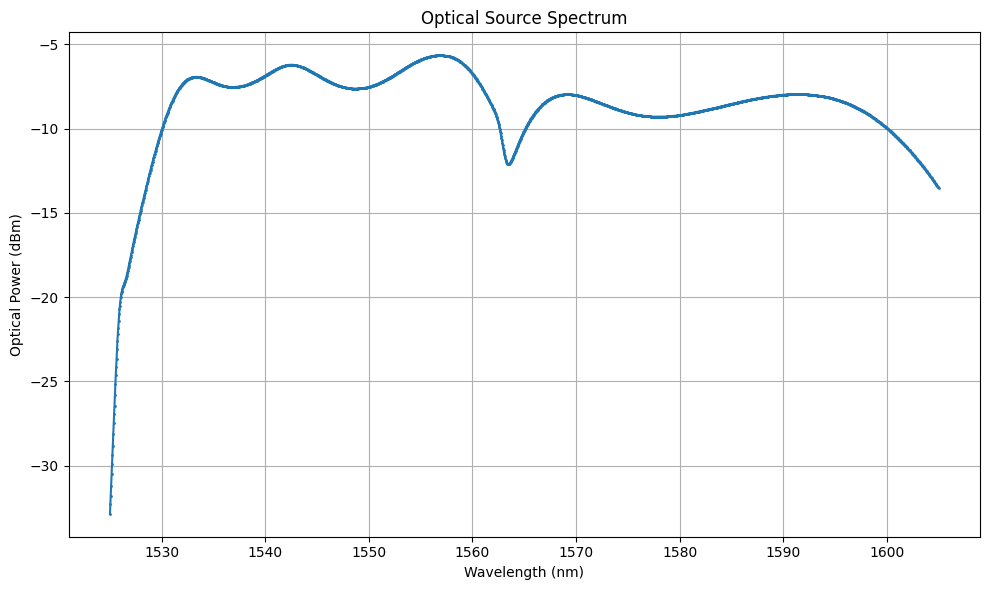

In [10]:
df = pd.read_csv('fuente.txt', sep='\t')

plt.figure(figsize=(10, 6))
plt.plot(df['Var1'], df['Var2'], marker='.', linestyle='-', markersize=2)
plt.title('Optical Source Spectrum')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Optical Power (dBm)')
plt.grid(True)
plt.tight_layout()

plt.show()

# Straight Waveguide

<Figure size 1000x500 with 0 Axes>

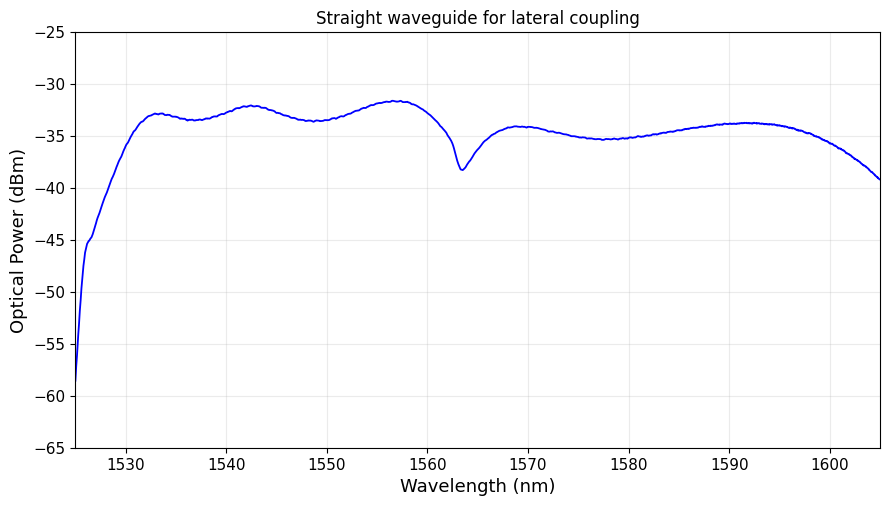

In [9]:
# Ignore metadata lines beginning with %
data = np.loadtxt('R20-A1-swg0-0.txt', comments='%')

# Extract columns
wavelength = data[:, 0]  # nm
power = data[:, 1]       # dBm

# Plot
plt.figure(figsize=(10, 5))

#plt.plot(wavelength, power, linewidth=1.2)

plt.figure(figsize=(9, 5))

plt.plot(wavelength, power, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Optical Power (dBm)", fontsize=13)

plt.xlim(1525, 1605)
plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.title('Straight waveguide for lateral coupling')
plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

<Figure size 1000x500 with 0 Axes>

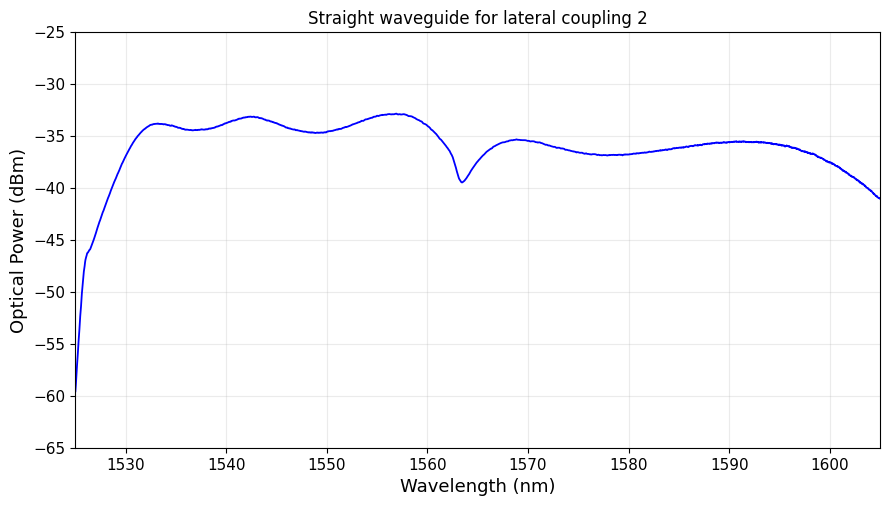

In [19]:
# Ignore metadata lines beginning with %
data2 = np.loadtxt('R20-A1-swg3-0.txt', comments='%')

# Extract columns
wavelength2 = data2[:, 0]  # nm
power2 = data2[:, 1]       # dBm

# Plot
plt.figure(figsize=(10, 5))

#plt.plot(wavelength, power, linewidth=1.2)

plt.figure(figsize=(9, 5))

plt.plot(wavelength2, power2, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Optical Power (dBm)", fontsize=13)

plt.xlim(1525, 1605)
plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.title('Straight waveguide for lateral coupling 2')
plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

<Figure size 1000x500 with 0 Axes>

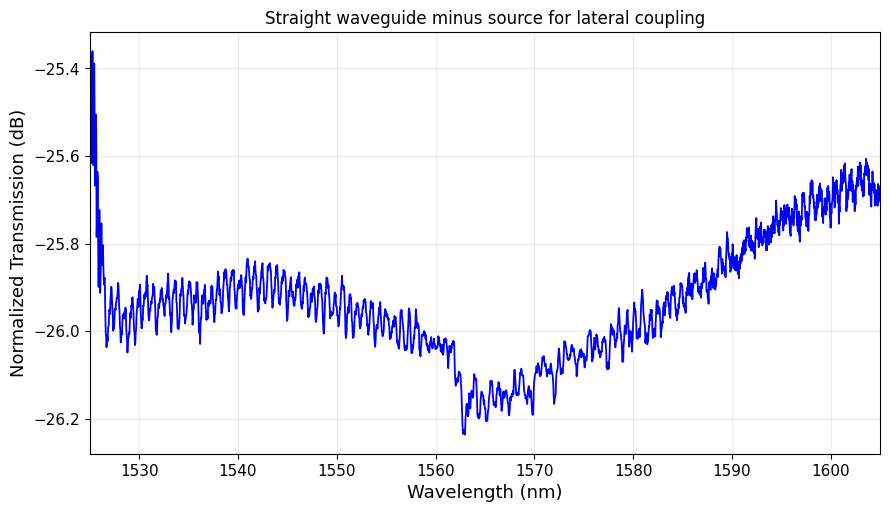

In [21]:
power_source_waveguide = power - df['Var2']
# Plot
plt.figure(figsize=(10, 5))

#plt.plot(wavelength, power, linewidth=1.2)

plt.figure(figsize=(9, 5))

plt.plot(wavelength, power_source_waveguide, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Normalized Transmission (dB)", fontsize=13)

plt.xlim(1525, 1605)
#plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
#plt.ylim(-25, -27)
plt.title('Straight waveguide minus source for lateral coupling')
#plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

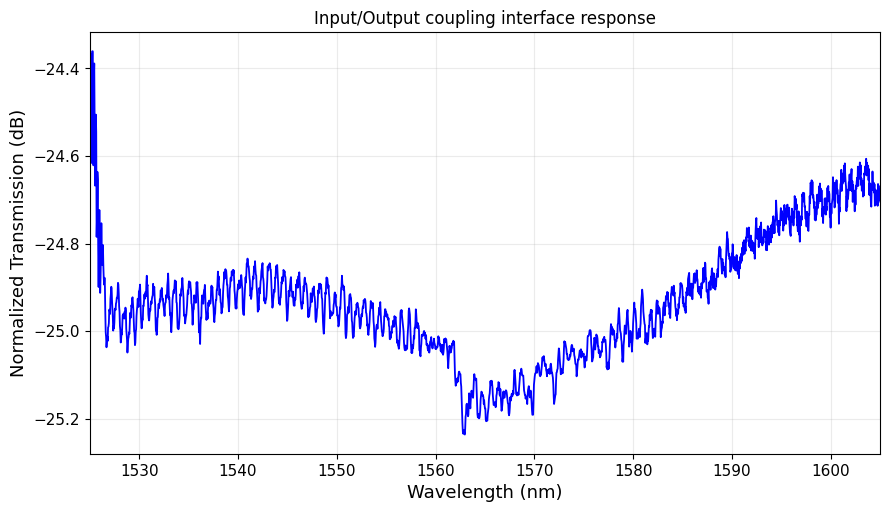

In [22]:
plt.figure(figsize=(9, 5))
# Le sumo 1dBm de las pérdidas propagación, para quedame con pérdidas de acoplo
plt.plot(wavelength, power_source_waveguide+1, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Normalized Transmission (dB)", fontsize=13)

plt.xlim(1525, 1605)
#plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
#plt.ylim(-25, -27)
plt.title('Input/Output coupling interface response')
#plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

# Ring resonator

<Figure size 1000x500 with 0 Axes>

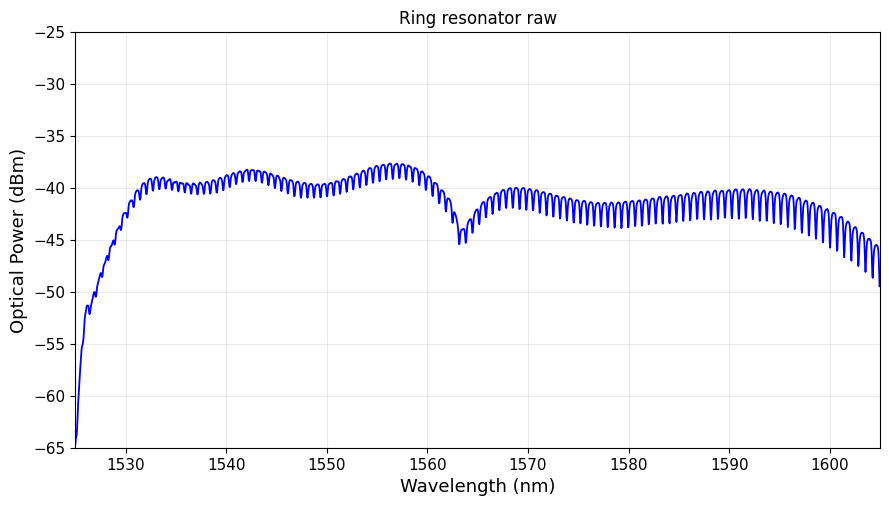

In [15]:
# Ignore metadata lines beginning with %
data = np.loadtxt('R20-A1-ring_resonator_1-0.txt', comments='%')

# Extract columns
wavelength = data[:, 0]  # nm
power_ring_raw = data[:, 1]       # dBm

# Plot
plt.figure(figsize=(10, 5))

#plt.plot(wavelength, power, linewidth=1.2)

plt.figure(figsize=(9, 5))

plt.plot(wavelength, power_ring_raw, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Optical Power (dBm)", fontsize=13)

plt.xlim(1525, 1605)
plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.title('Ring resonator raw')
#plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

In [16]:
print(f'Range of wavelength is {np.min(wavelength)} to {np.max(wavelength)}')

Range of wavelength is 1525.0 to 1605.0


<Figure size 1000x500 with 0 Axes>

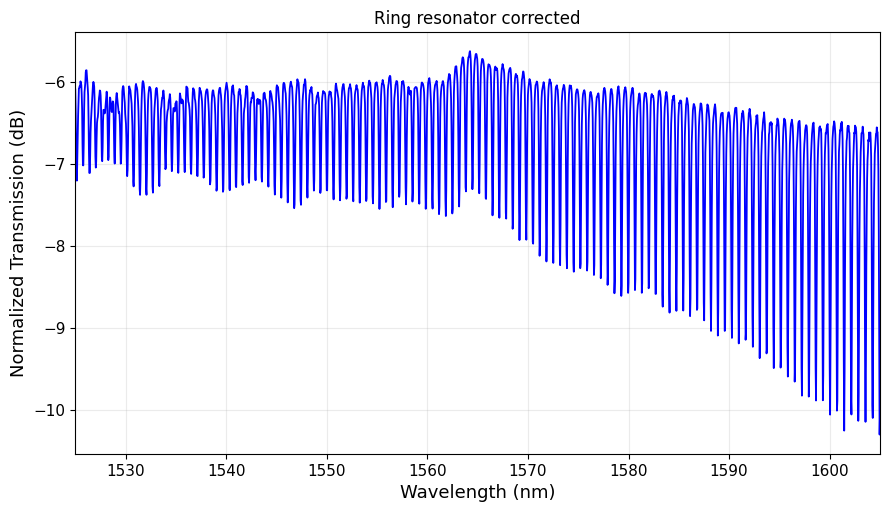

In [23]:
power_ring_corrected = power_ring_raw - power
plt.figure(figsize=(10, 5))

#plt.plot(wavelength, power, linewidth=1.2)

plt.figure(figsize=(9, 5))

plt.plot(wavelength, power_ring_corrected, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Normalized Transmission (dB)", fontsize=13)

plt.xlim(1525, 1605)
#plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.title('Ring resonator corrected')
#plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

In [25]:
max_power_ring = np.max(power_ring_corrected)
print(f'Insertion loss of the ring resonator is: {max_power_ring} dBm')

Insertion loss of the ring resonator is: -5.624784599999998 dBm


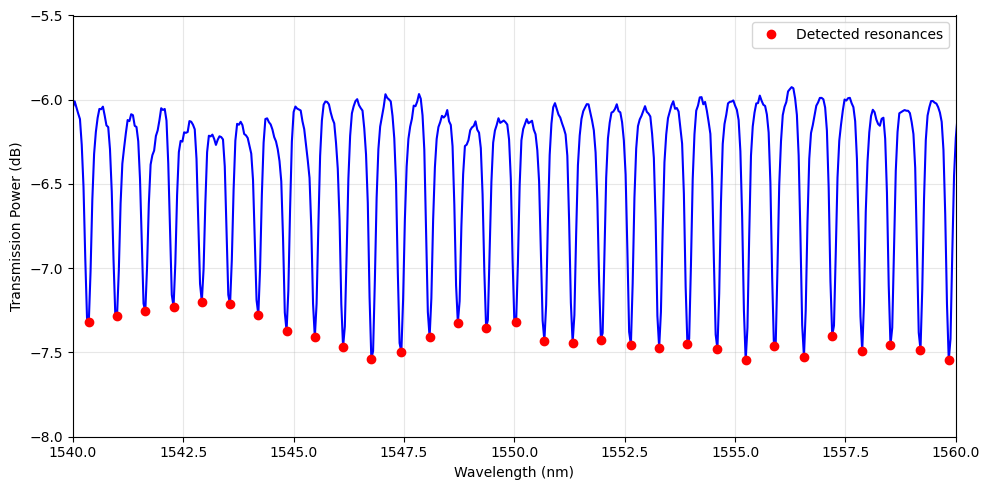

Mean FSR around 1550 nm: 0.6500 ± 0.0173 nm
Optical length (n_g * L): 3682.63 +/- 97.24 um
Physical ring length L:   1878.89 +/- 49.61 um
Ring radius R:      299.04  ± 7.90 um


In [57]:
resonance_dips, _ = find_peaks(-power_ring_corrected, prominence=0.3, distance=5)
resonance_peaks, _ = find_peaks(power_ring_corrected, prominence=0.3, distance=5)
wl_res = wavelength[resonance_dips]

# Local FSR [nm] and center wavelengths [nm] between consecutive resonances
fsr_nm = np.diff(wl_res)
wl_center = 0.5 * (wl_res[:-1] + wl_res[1:])

# Optical path length n_g * L in micrometers [um]
ng_L_um = (wl_center**2 / fsr_nm) * 1e-3

# Plot detected resonances
plt.figure(figsize=(10, 5))
plt.plot(wavelength, power_ring_corrected, "b-")
plt.plot(wl_res, power_ring_corrected[resonance_dips],
         "ro", label="Detected resonances")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission Power (dB)")
plt.xlim(1540,1560)
plt.ylim(-8,-5.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Provide your platform's group index at 1550 nm
n_g = 1.96  # <-- Replace with your waveguide's group index
L_um = ng_L_um / n_g

print(f"Mean FSR around 1550 nm: {np.mean(fsr_nm[(wl_center > 1545) & (wl_center < 1555)]):.4f} ± {np.std(fsr_nm[(wl_center > 1545) & (wl_center < 1555)]):.4f} nm")
print(f"Optical length (n_g * L): {np.mean(ng_L_um):.2f} +/- {np.std(ng_L_um):.2f} um")
print(f"Physical ring length L:   {np.mean(L_um):.2f} +/- {np.std(L_um):.2f} um")
print(f"Ring radius R:      {np.mean(L_um) / (2 * np.pi):.2f}  ± {1/(2*np.pi)*np.std(L_um):.2f} um")

Now considering the dependence of n group with the wavelength

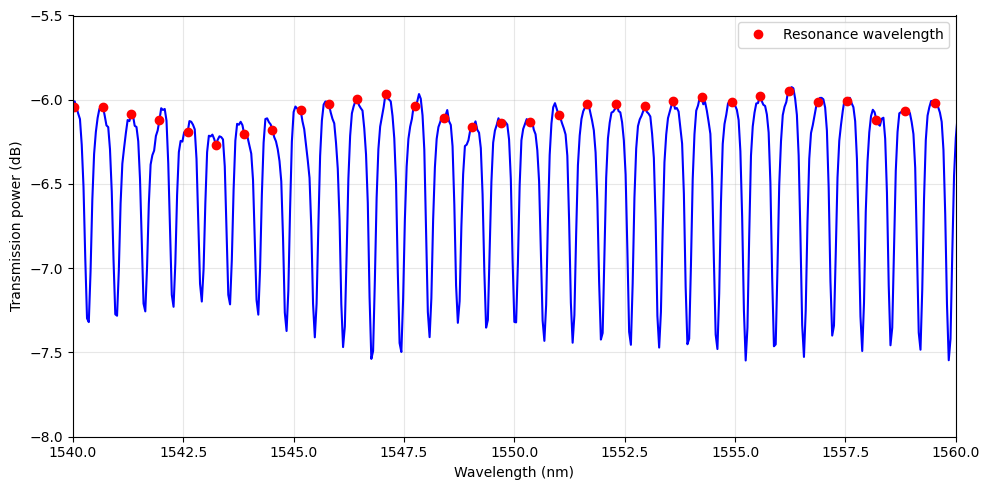

In [45]:
# Plot wavelength resonances
resonance_indices = np.array([
    np.abs(wavelength - wl).argmin()
    for wl in wl_center
])

plt.figure(figsize=(10, 5))
plt.plot(wavelength, power_ring_corrected, "b-")
plt.plot(wl_center, power_ring_corrected[resonance_indices],
         "ro", label="Resonance wavelength")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission power (dB)")
plt.xlim(1540,1560)
plt.ylim(-8,-5.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Detected 120 resonances
Mean FSR: 0.6649 nm
Estimated L: 1892.12 ± 49.96 um


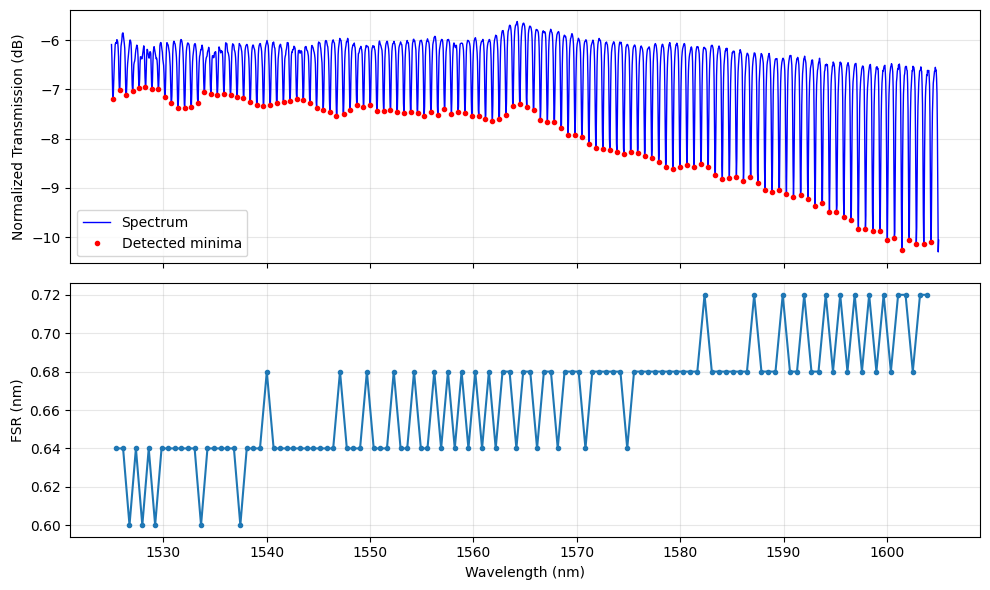

In [72]:
# Assumes:
# lambda_sweep      -> 1D array of wavelengths (nm)
# transmission_db   -> 1D array of Normalized Transmission (dB)
# wavelength_modes  -> 1D array of mode-solver wavelengths (same units as lambda_sweep!)
# ng                -> 1D array of group index at wavelength_modes

# 1. Detect resonance minima
d_lambda = np.median(np.diff(lambda_sweep))
min_spacing_nm = 0.4  # ~half the ~0.7 nm FSR to prevent double-detection on noisy dips

resonance_dips, _ = find_peaks(-power_ring_corrected, prominence=0.25, distance=10)

lambda_res = wavelength[resonance_dips]

# 2. Compute FSR and central wavelength for each consecutive resonance pair
fsr_exp = np.diff(lambda_res)                        # lambda[i+1] - lambda[i]
lambda_c = 0.5 * (lambda_res[:-1] + lambda_res[1:])  # central wavelength of each FSR

# 3. Interpolate ng directly at each central wavelength
ng_c = np.interp(lambda_c, wavelength_modes, ng)

# Optional: extract cavity length L (same length unit as lambda_c, e.g., nm -> um)
L_nm = (lambda_c**2) / (ng_c * fsr_exp)
L_um = L_nm * 1e-3

print(f"Detected {len(lambda_res)} resonances")
print(f"Mean FSR: {np.mean(fsr_exp):.4f} nm")
print(f"Estimated L: {np.mean(L_um):.2f} ± {np.std(L_um):.2f} um")

# 4. Diagnostic plot: verify peak detection + inspect FSR(lambda_c)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(wavelength, power_ring_corrected, "b-", lw=1, label="Spectrum")
ax1.plot(lambda_res, power_ring_corrected[resonance_dips], "ro", ms=3, label="Detected minima")
ax1.set_ylabel("Normalized Transmission (dB)")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(lambda_c, fsr_exp, "o-", ms=3)
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("FSR (nm)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Detected 120 resonances
Mean FSR: 0.66486 nm
Estimated L: 1890.969 +/- 17.131 um


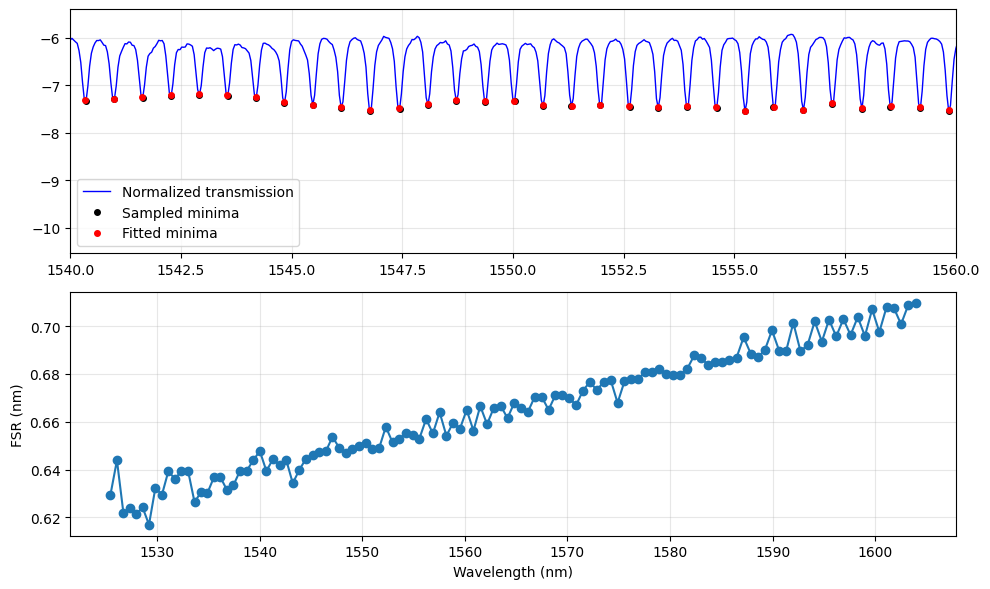

In [85]:
# Use consistent variable names
x = np.asarray(wavelength)
y = np.asarray(power_ring_corrected)

# Wavelength sampling interval
d_lambda = np.median(np.diff(x))

# Minimum distance between detected resonances
min_spacing_nm = 0.4
distance_pts = max(1, int(round(min_spacing_nm / d_lambda)))

# 1. Detect resonance minima
resonance_dips, _ = find_peaks(
    -y,
    prominence=0.25,
    distance=distance_pts
)

# 2. Refine resonance wavelength using parabolic fitting
def refine_minimum(x, y, index, half_window=2):

    i1 = max(0, index - half_window)
    i2 = min(len(x), index + half_window + 1)

    x_fit = x[i1:i2]
    y_fit = y[i1:i2]

    if len(x_fit) < 3:
        return x[index]

    # Center coordinates to improve numerical stability
    x_local = x_fit - x[index]

    # Fit y = a*x^2 + b*x + c
    a, b, c = np.polyfit(x_local, y_fit, 2)

    # Calculate parabola vertex
    if a <= 0:
        return x[index]

    x_vertex = -b / (2 * a)

    # Reject extrapolated or unrealistic minima
    if x_vertex < x_local.min() or x_vertex > x_local.max():
        return x[index]

    return x[index] + x_vertex


# Refined resonance wavelengths
lambda_res = np.array([
    refine_minimum(x, y, i, half_window=2)
    for i in resonance_dips
])

# 3. Calculate FSR
fsr_exp = np.diff(lambda_res)

lambda_c = 0.5 * (lambda_res[:-1] + lambda_res[1:])
# 4. Interpolate group index
ng_c = np.interp(lambda_c, wavelength_modes, ng)

# 5. Calculate cavity length
L_nm = lambda_c**2 / (ng_c * fsr_exp)
L_um = L_nm * 1e-3
print(f"Detected {len(lambda_res)} resonances")
print(f"Mean FSR: {np.mean(fsr_exp):.5f} nm")
print(f"Estimated L: {np.mean(L_um):.3f} "
      f"+/- {np.std(L_um):.3f} um")

# 6. Diagnostic plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))

ax1.plot(x, y, "b-", lw=1, label="Normalized transmission")

# Original detected positions
ax1.plot(x[resonance_dips], y[resonance_dips],
         "ko", ms=4, label="Sampled minima")

# Refined positions
ax1.plot(lambda_res,
         np.interp(lambda_res, x, y),
         "ro", ms=4, label="Fitted minima")

ax1.set_xbound(1540,1560)
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(lambda_c, fsr_exp, "o-")
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("FSR (nm)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

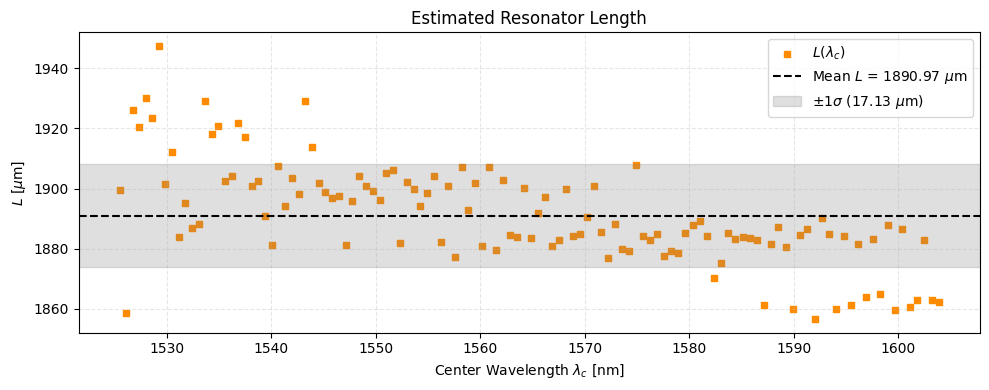

-----------------------------------
Mean ring length: 1890.969 µm
Standard deviation: 17.131 µm
Minimum ring length: 1856.596 µm
Maximum ring length: 1947.441 µm
-----------------------------------


In [86]:
# 7. Plot resonator length as a function of wavelength

# Calculate mean and standard deviation
L_mean = np.mean(L_um)
L_std = np.std(L_um)

fig, ax = plt.subplots(figsize=(10, 4))

# Individual resonator length estimates
ax.scatter(
    lambda_c,
    L_um,
    color="darkorange",
    marker="s",
    s=18,
    label=r"$L(\lambda_c)$"
)

# Mean resonator length
ax.axhline(
    L_mean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=fr"Mean $L$ = {L_mean:.2f} $\mu$m"
)

# +/- 1 standard deviation region
ax.axhspan(
    L_mean - L_std,
    L_mean + L_std,
    color="gray",
    alpha=0.25,
    label=fr"$\pm 1\sigma$ ({L_std:.2f} $\mu$m)"
)

# Axis labels
ax.set_xlabel(r"Center Wavelength $\lambda_c$ [nm]")
ax.set_ylabel(r"$L$ [$\mu$m]")

ax.set_title("Estimated Resonator Length")

ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.3)

# Avoid scientific notation on the y-axis
ax.ticklabel_format(axis="y", style="plain", useOffset=False)

plt.tight_layout()
plt.show()

print("-----------------------------------")
print(f"Mean ring length: {L_mean:.3f} µm")
print(f"Standard deviation: {L_std:.3f} µm")
print(f"Minimum ring length: {np.min(L_um):.3f} µm")
print(f"Maximum ring length: {np.max(L_um):.3f} µm")
print("-----------------------------------")

# Mach Zehnder

<Figure size 1000x500 with 0 Axes>

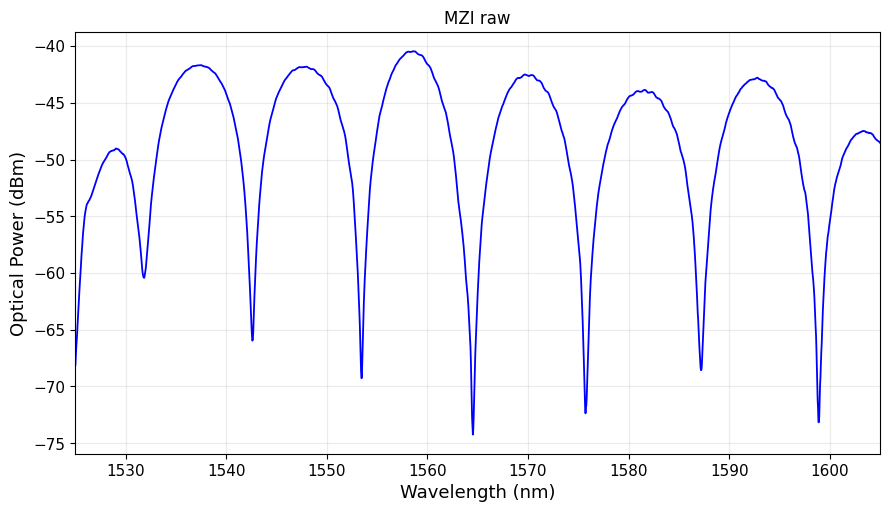

In [7]:
# Ignore metadata lines beginning with %
data = np.loadtxt('Rna-A1-mzi-na.txt', comments='%')

# Extract columns
wavelength = data[:, 0]  # nm
power_mzi_raw = data[:, 1]       # dBm

# Plot
plt.figure(figsize=(10, 5))

#plt.plot(wavelength, power, linewidth=1.2)

plt.figure(figsize=(9, 5))

plt.plot(wavelength, power_mzi_raw, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Optical Power (dBm)", fontsize=13)

plt.xlim(1525, 1605)
#plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.title('MZI raw')
#plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

<Figure size 1000x500 with 0 Axes>

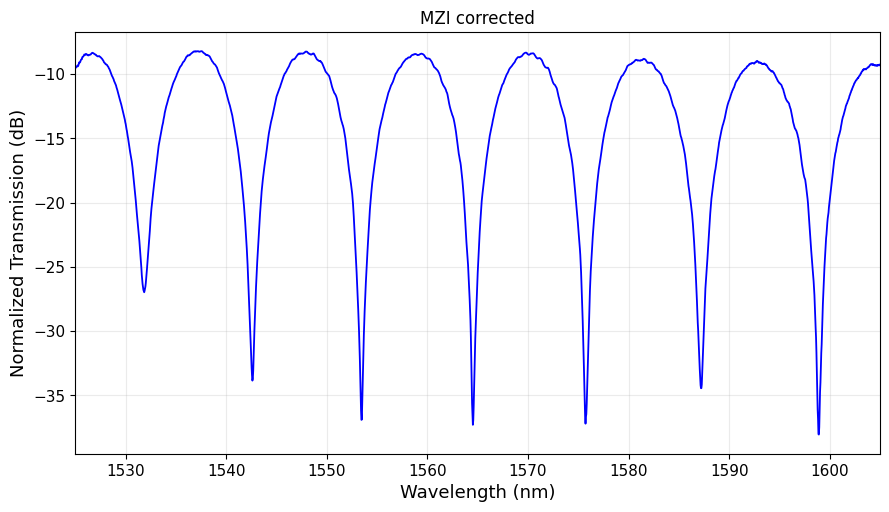

In [10]:
power_mzi_corrected = power_mzi_raw - power
# Plot
plt.figure(figsize=(10, 5))

#plt.plot(wavelength, power, linewidth=1.2)

plt.figure(figsize=(9, 5))

plt.plot(wavelength, power_mzi_corrected, 'b-', linewidth=1.3)

plt.xlabel("Wavelength (nm)", fontsize=13)
plt.ylabel("Normalized Transmission (dB)", fontsize=13)

plt.xlim(1525, 1605)
#plt.ylim(-65, -25)

plt.tick_params(axis='both', labelsize=11)
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.title('MZI corrected')
#plt.savefig("OSA_spectrum.png", dpi=600)
plt.show()

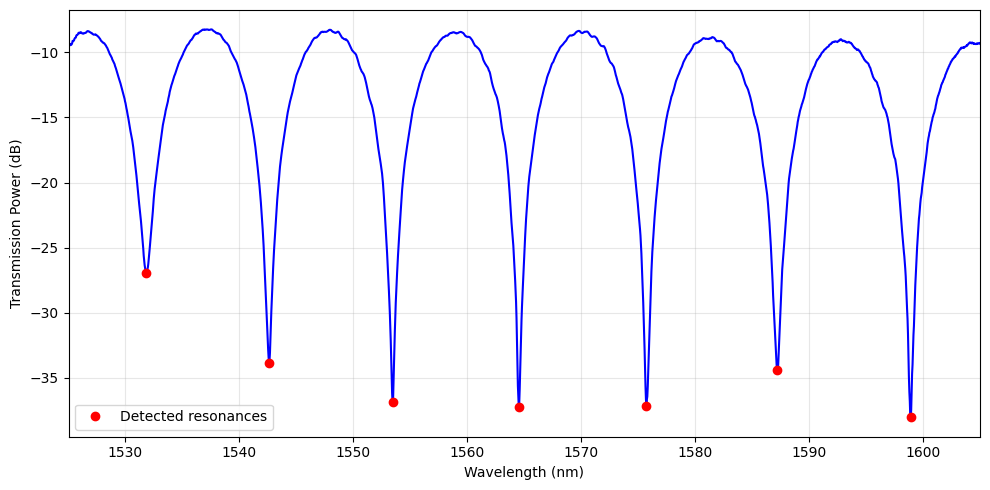

Mean FSR around 1550 nm: 10.8400 ± 0.0000 nm
Optical length (n_g * L): 219.09 +/- 1.49 um
Physical ring length L:   111.78 +/- 0.76 um
Ring radius R:      17.79  ± 0.12 um


In [12]:
resonance_dips, _ = find_peaks(-power_mzi_corrected, prominence=0.3, distance=5)
wl_res = wavelength[resonance_dips]

# Local FSR [nm] and center wavelengths [nm] between consecutive resonances
fsr_nm = np.diff(wl_res)
wl_center = 0.5 * (wl_res[:-1] + wl_res[1:])

# Optical path length n_g * L in micrometers [um]
ng_L_um = (wl_center**2 / fsr_nm) * 1e-3

# Plot detected resonances
plt.figure(figsize=(10, 5))
plt.plot(wavelength,power_mzi_corrected, "b-")
plt.plot(wl_res,power_mzi_corrected[resonance_dips],
         "ro", label="Detected resonances")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission Power (dB)")
plt.legend()
plt.xlim(1525,1605)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Provide your platform's group index at 1550 nm
n_g = 1.96  # <-- Replace with your waveguide's group index
L_um = ng_L_um / n_g

print(f"Mean FSR around 1550 nm: {np.mean(fsr_nm[(wl_center > 1545) & (wl_center < 1555)]):.4f} ± {np.std(fsr_nm[(wl_center > 1545) & (wl_center < 1555)]):.4f} nm")
print(f"Optical length (n_g * L): {np.mean(ng_L_um):.2f} +/- {np.std(ng_L_um):.2f} um")
print(f"Physical ring length L:   {np.mean(L_um):.2f} +/- {np.std(L_um):.2f} um")
print(f"Ring radius R:      {np.mean(L_um) / (2 * np.pi):.2f}  ± {1/(2*np.pi)*np.std(L_um):.2f} um")

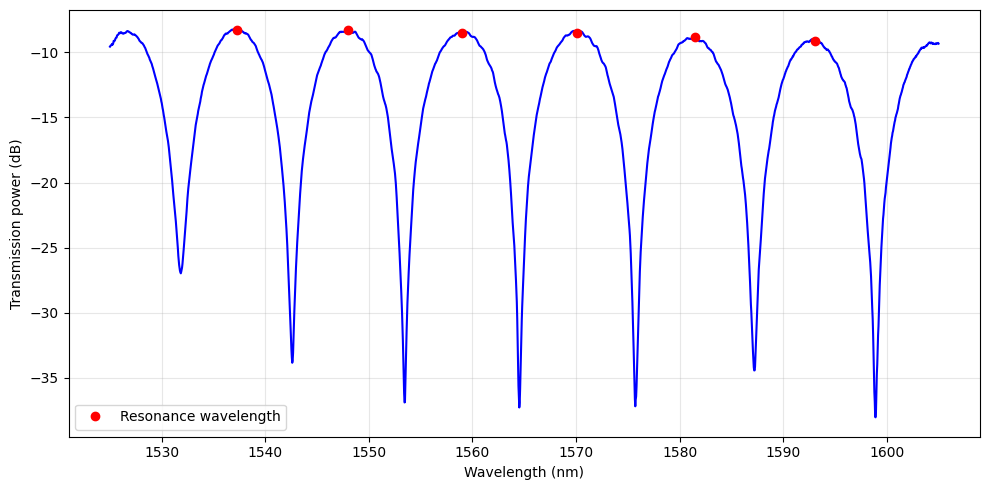

In [13]:
# Plot wavelength resonances
resonance_indices = np.array([
    np.abs(wavelength - wl).argmin()
    for wl in wl_center
])

plt.figure(figsize=(10, 5))
plt.plot(wavelength, power_mzi_corrected, "b-")
plt.plot(wl_center, power_mzi_corrected[resonance_indices],
         "ro", label="Resonance wavelength")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission power (dB)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Detected 7 resonances
Mean FSR: 11.1800 nm
Estimated L: 112.57 ± 0.77 um


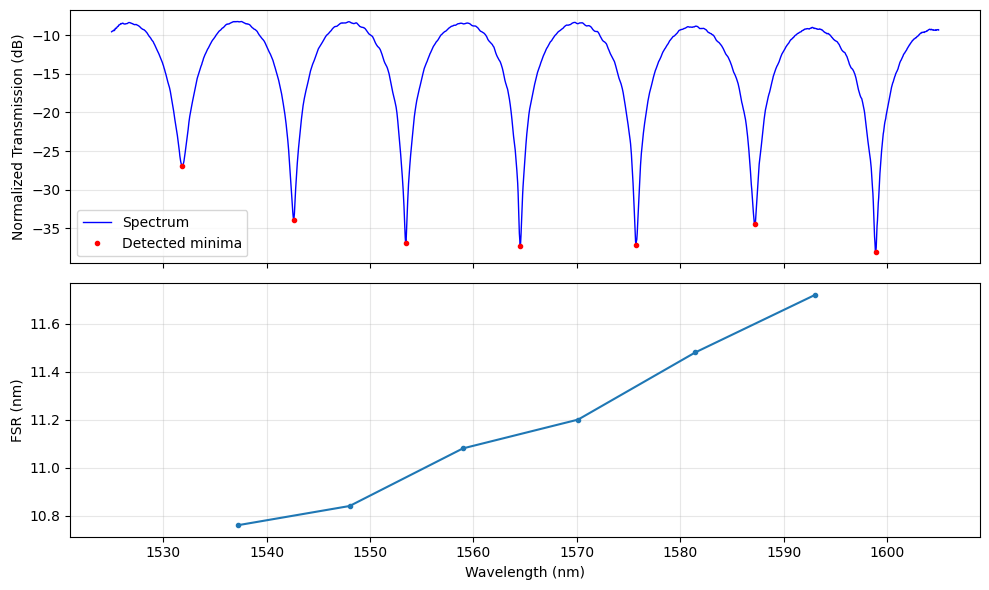

In [14]:
# Assumes:
# lambda_sweep      -> 1D array of wavelengths (nm)
# transmission_db   -> 1D array of Normalized Transmission (dB)
# wavelength_modes  -> 1D array of mode-solver wavelengths (same units as lambda_sweep!)
# ng                -> 1D array of group index at wavelength_modes

# 1. Detect resonance minima
min_spacing_nm = 0.4  # ~half the ~0.7 nm FSR to prevent double-detection on noisy dips

resonance_dips, _ = find_peaks(-power_mzi_corrected, prominence=0.25, distance=10)

lambda_res = wavelength[resonance_dips]

# 2. Compute FSR and central wavelength for each consecutive resonance pair
fsr_exp = np.diff(lambda_res)                        # lambda[i+1] - lambda[i]
lambda_c = 0.5 * (lambda_res[:-1] + lambda_res[1:])  # central wavelength of each FSR

# 3. Interpolate ng directly at each central wavelength
ng_c = np.interp(lambda_c, wavelength_modes, ng)

# Optional: extract cavity length L (same length unit as lambda_c, e.g., nm -> um)
L_nm = (lambda_c**2) / (ng_c * fsr_exp)
L_um = L_nm * 1e-3

print(f"Detected {len(lambda_res)} resonances")
print(f"Mean FSR: {np.mean(fsr_exp):.4f} nm")
print(f"Estimated L: {np.mean(L_um):.2f} ± {np.std(L_um):.2f} um")

# 4. Diagnostic plot: verify peak detection + inspect FSR(lambda_c)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(wavelength, power_mzi_corrected, "b-", lw=1, label="Spectrum")
ax1.plot(lambda_res,power_mzi_corrected[resonance_dips], "ro", ms=3, label="Detected minima")
ax1.set_ylabel("Normalized Transmission (dB)")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(lambda_c, fsr_exp, "o-", ms=3)
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel("FSR (nm)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

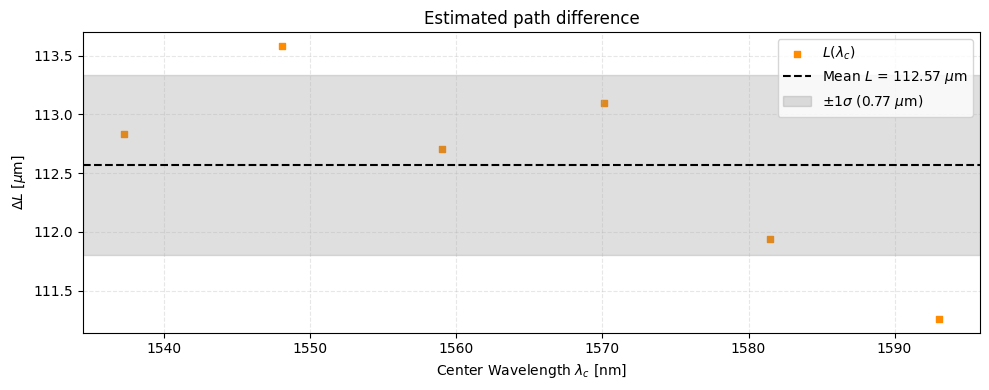

-----------------------------------
Mean length: 112.568 µm
Standard deviation: 0.766 µm
Minimum length: 111.257 µm
Maximum length: 113.583 µm
-----------------------------------


In [15]:
# 7. Plot resonator length as a function of wavelength

# Calculate mean and standard deviation
L_mean = np.mean(L_um)
L_std = np.std(L_um)

fig, ax = plt.subplots(figsize=(10, 4))

# Individual resonator length estimates
ax.scatter(
    lambda_c,
    L_um,
    color="darkorange",
    marker="s",
    s=18,
    label=r"$L(\lambda_c)$"
)

# Mean resonator length
ax.axhline(
    L_mean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=fr"Mean $L$ = {L_mean:.2f} $\mu$m"
)

# +/- 1 standard deviation region
ax.axhspan(
    L_mean - L_std,
    L_mean + L_std,
    color="gray",
    alpha=0.25,
    label=fr"$\pm 1\sigma$ ({L_std:.2f} $\mu$m)"
)

# Axis labels
ax.set_xlabel(r"Center Wavelength $\lambda_c$ [nm]")
ax.set_ylabel(r"$\Delta L$ [$\mu$m]")

ax.set_title("Estimated path difference")

ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.3)

# Avoid scientific notation on the y-axis
ax.ticklabel_format(axis="y", style="plain", useOffset=False)

plt.tight_layout()
plt.show()

print("-----------------------------------")
print(f"Mean length: {L_mean:.3f} µm")
print(f"Standard deviation: {L_std:.3f} µm")
print(f"Minimum length: {np.min(L_um):.3f} µm")
print(f"Maximum length: {np.max(L_um):.3f} µm")
print("-----------------------------------")

In [27]:
neff_sweep = np.interp(
    lambda_sweep,
    wavelength_modes,
    neff
)
ng_sweep = np.interp(
    lambda_sweep,
    wavelength_modes,
    ng
)

results = compare_mzi(
    wavelength=wavelength,
    power_mzi_corrected=power_mzi_corrected,
    wavelength_modes=wavelength_modes,
    neff=neff_sweep,
    ng=ng_sweep,
    delta_L_um=113
)

ValueError: Mode solver wavelength range must cover the experiment.